In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from tqdm import tqdm
import sys
import os
import yaml
import mdtraj as md

sys.path.append('..')
from src import visualisation as vis
from src import constants
from src import utils
from src.analysis.slim import TwoChain, _calc_Kd

In [2]:
# Looping over scan
ks = []
Kds = []

#'sh3-prm' 'psd-cript'
system = 'sh3-prm'
scan_dir = f'../sim/scan/{system}'
for k_dir in tqdm(sorted(os.listdir(scan_dir))):

    k = float(k_dir.split('=')[-1])

    try:
        kd_csv = os.path.join(scan_dir, k_dir, 'kd.csv')

        if not os.path.exists(kd_csv):
            TwoChain.get_Kd_sem(
                top_pdb = os.path.join(scan_dir, k_dir, 'top.pdb'),
                traj_dcd = os.path.join(scan_dir, k_dir, f'{system}.dcd'),
                specific_interactions_txt = os.path.join(scan_dir, k_dir, 'specific_interactions.txt'),   
                to_csv = kd_csv
            )
            
        Kd = pd.read_csv(kd_csv).values[0]
        
    # Simulation not run yet
    except OSError:
        Kd = (np.NaN, np.NaN, np.NaN)
    
    ks.append(k)
    Kds.append(Kd)

ks = np.array(ks)
Kds = np.array(Kds)


100%|██████████| 51/51 [00:00<00:00, 52.03it/s]


In [3]:
dG = lambda Kd: constants.R * 298.15 * np.log(Kd)
dGs = dG(Kds[:,[0,2,1]])

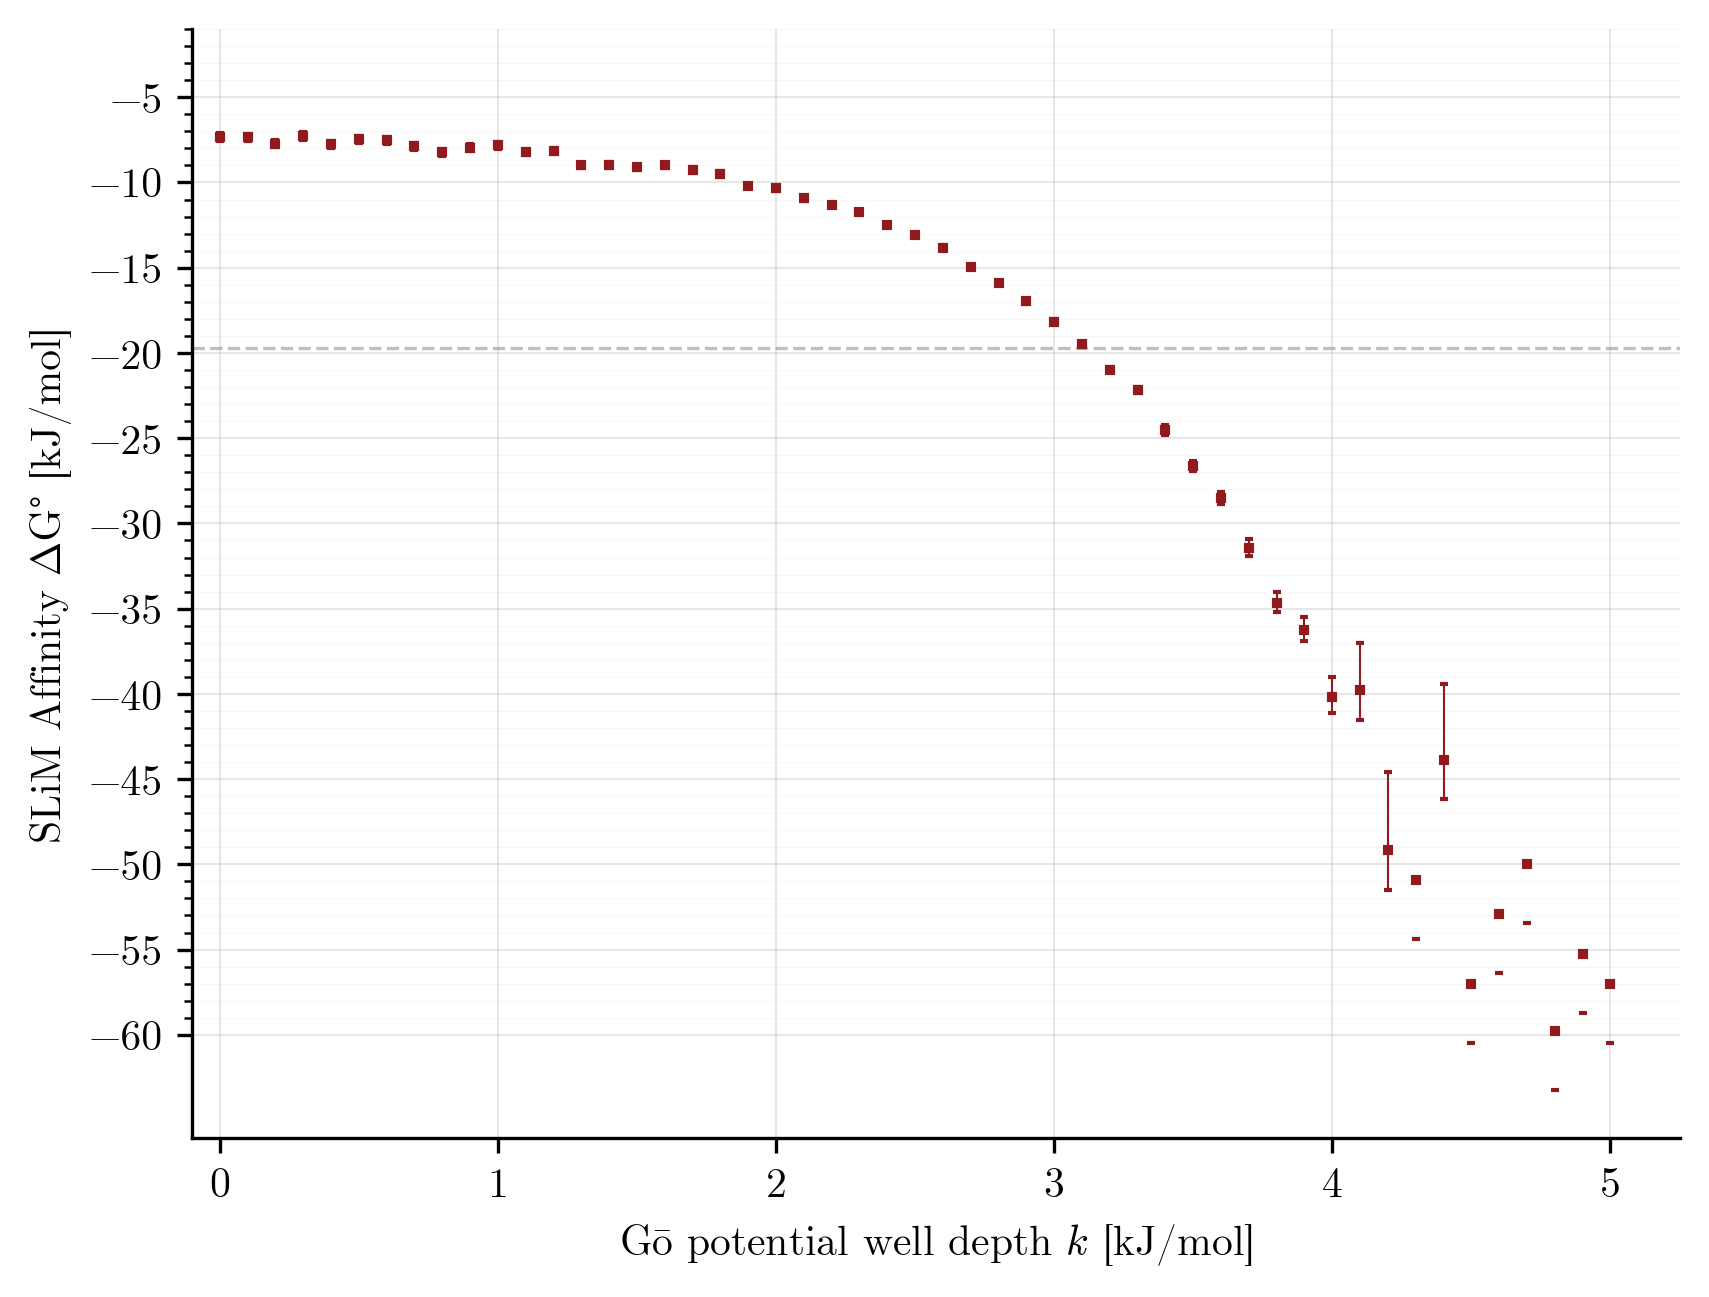

In [4]:
yerr = (dGs[:,[1,2]] - dGs[:,0][:,np.newaxis]) * np.array([1,-1])
yerr = np.where(yerr > -np.inf, yerr, np.NaN)
plt.errorbar(
    x = ks, y = dGs[:,0], yerr = yerr.T,
    fmt = 's', ms=1.5, capsize=1, elinewidth=0.5
)
xlims = plt.xlim(-0.1)
true_Kd = 350e-6
plt.hlines(dG(true_Kd), *xlims, linestyles='dashed', alpha=0.5, color='grey', linewidth=0.8)
plt.ylabel('SLiM Affinity ΔG° [kJ/mol]')
plt.xlabel('Gō potential well depth $k$ [kJ/mol]')
plt.yticks(np.arange(-60,0,5),minor=False)
plt.yticks(np.arange(-60,0,1),minor=True)
plt.grid(which='major', alpha=0.3, linewidth=0.5)
plt.grid(which='minor', alpha=0.1, linewidth=0.2)


In [ ]:
from src.analysis.blocking import BlockAnalysis

ks = [1,2,3,4]
nframes_range = np.geomspace(100,30000,30).astype(int)
deltaG_errors = np.zeros(shape=(len(nframes_range), len(ks)), dtype=float)
for i, k in enumerate(ks):

    k_dir = f'k={k:.2f}'
    top_pdb: str = os.path.join(scan_dir, k_dir, 'top.pdb')
    traj_dcd: str = os.path.join(scan_dir, k_dir, 'sh3-prm.dcd')
    specific_interactions_txt: str = os.path.join(scan_dir, k_dir, 'specific_interactions.txt')
    contact_eqdist_fold: float=2
    contact_fraction_bound: float=0.1
    n_SE: float=1

    # Load contacts
    specific_interactions = utils.parse_specific_interactions(specific_interactions_txt)

    # Load trajectory
    traj = md.load(traj_dcd, top=top_pdb)

    # Calculate concentration from topology
    chains = 1
    volume = traj.unitcell_volumes[0] * 1e-24 # L
    concentration = (chains) / (constants.N_A * volume) # M

    # Calculate contact fraction in traj
    contact_indices = specific_interactions.iloc[:,[1,3]].astype(int).values - 1
    contact_eqdists = specific_interactions.iloc[:,4].astype(float).values
    acceptor_resids = traj.topology.select('chainid 0')
    donor_resids = traj.topology.select('chainid 1')
    contact_resiuds = np.vstack((acceptor_resids[contact_indices[:,0]], donor_resids[contact_indices[:,1]])).T
    contact_dists = md.compute_distances(traj, contact_resiuds, periodic=True)

    # Kd blocking estimates
    bound_state = (contact_dists <= contact_eqdists*contact_eqdist_fold).mean(axis=1) > contact_fraction_bound

    for j, nframes in tqdm(enumerate(nframes_range), total=len(nframes_range)):
        ba = BlockAnalysis(bound_state[:nframes])
        ba.SEM()
        fraction_bound = ba.av
        fraction_bound_sem = ba.sem
        Kd = _calc_Kd(fraction_bound, concentration)
        Kd_upper = _calc_Kd(max(0, fraction_bound - n_SE*fraction_bound_sem), concentration)
        Kd_lower = _calc_Kd(min(1, fraction_bound + n_SE*fraction_bound_sem), concentration)
        deltaG, deltaG_lower, deltaG_upper = dG(Kd), dG(Kd_upper), dG(Kd_lower)
        deltaG_error =  (deltaG_lower - deltaG_upper) / 2
        deltaG_errors[j,i] = deltaG_error

  0%|          | 0/30 [00:00<?, ?it/s]/tmp/ipykernel_2944824/1041390353.py:1: RuntimeWarning: divide by zero encountered in log
  dG = lambda Kd: constants.R * 298.15 * np.log(Kd)
/tmp/ipykernel_2944824/3678074937.py:47: RuntimeWarning: invalid value encountered in scalar subtract
  deltaG_error =  (deltaG_lower - deltaG_upper) / 2
100%|██████████| 30/30 [00:02<00:00, 10.97it/s]

(0.0, 4.0)

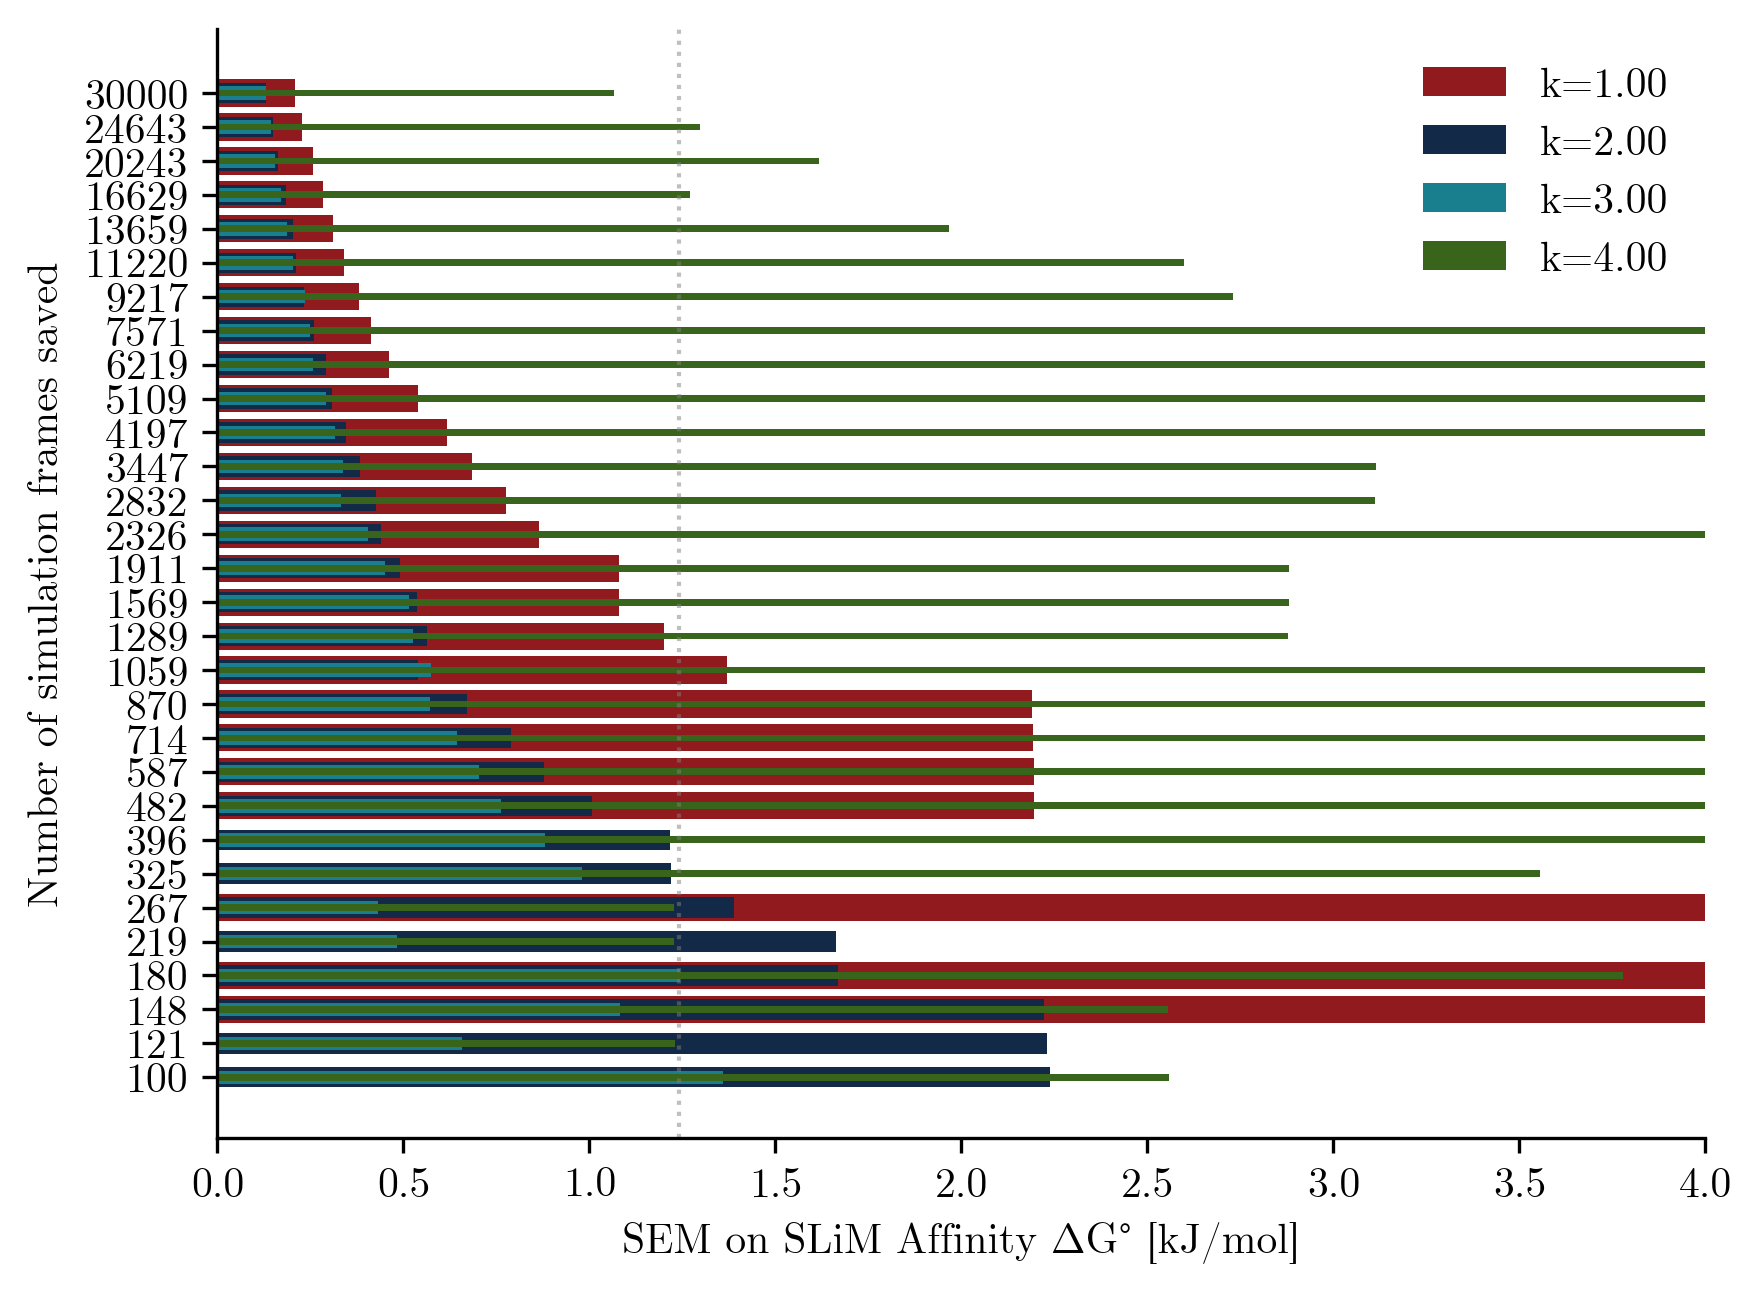

In [ ]:
for i, k in enumerate(ks):
    plt.barh(nframes_range.astype(str), deltaG_errors[:,i], label=f'{k=:.2f}', height=0.8 - i*0.8/len(ks))
ylim = plt.ylim()
plt.vlines(constants.R*298.15/2, *ylim, linestyle='dotted', color='grey', alpha=0.5, linewidth=1)
plt.ylim(ylim)
plt.ylabel("Number of simulation frames saved")
plt.xlabel("SEM on SLiM Affinity ΔG° [kJ/mol]")
plt.legend(frameon=False)
plt.xlim(0,4)